# Stable Diffusion Demo 1: VAE Compression and Reconstruction

In Stable Diffusion, images are not processed directly in pixel space.  
Instead, they are first compressed into a smaller **latent space** using a Variational Autoencoder (VAE).  
Diffusion then happens in this latent space, which is much smaller and more efficient.

In this demo, we:
1. Load a Fashion-MNIST image
2. Convert it to RGB and resize it
3. Encode it into the VAE latent space
4. Decode it back into an image

This helps us understand the first key idea behind Stable Diffusion:  
**compress first, then work in latent space.**

In [1]:
!pip -q install -U diffusers transformers accelerate

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from tqdm.auto import tqdm
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt
from torchvision import datasets, transforms

In [3]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

Using device: cuda


In [4]:
from diffusers import AutoencoderKL

## Load Fashion-MNIST

Fashion-MNIST images are grayscale and very small (28x28).  
The Stable Diffusion VAE expects 3-channel RGB images, so we:
- resize to 64x64
- convert grayscale to 3 channels
- normalize to [-1, 1]

In [5]:
transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

In [6]:
dataset = datasets.FashionMNIST(root="./data", train=True, download=True, transform=transform)

In [7]:
image, label = dataset[0]
print("Image shape:", image.shape)
print("Label:", label)

Image shape: torch.Size([3, 64, 64])
Label: 9


In [8]:
class_names = dataset.classes
print("Class name:", class_names[label])

Class name: Ankle boot


## Visualize the input image

The normalized tensor is in the range [-1, 1], so we convert it back to [0, 1] for display.

In [9]:
def denorm(x):
    return (x.clamp(-1, 1) + 1) / 2

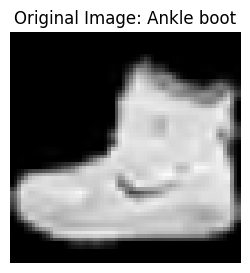

In [10]:
img_show = denorm(image).permute(1, 2, 0).cpu().numpy()

plt.figure(figsize=(3,3))
plt.imshow(img_show)
plt.title(f"Original Image: {class_names[label]}")
plt.axis("off")
plt.show()

## Load the Stable Diffusion VAE

We use the pretrained VAE from Stable Diffusion.  
This VAE converts an image into a smaller latent representation.

In [11]:
vae = AutoencoderKL.from_pretrained("stabilityai/sd-vae-ft-mse").to(device)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


In [12]:
vae.eval()

AutoencoderKL(
  (encoder): Encoder(
    (conv_in): Conv2d(3, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (down_blocks): ModuleList(
      (0): DownEncoderBlock2D(
        (resnets): ModuleList(
          (0-1): 2 x ResnetBlock2D(
            (norm1): GroupNorm(32, 128, eps=1e-06, affine=True)
            (conv1): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
            (norm2): GroupNorm(32, 128, eps=1e-06, affine=True)
            (dropout): Dropout(p=0.0, inplace=False)
            (conv2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
            (nonlinearity): SiLU()
          )
        )
        (downsamplers): ModuleList(
          (0): Downsample2D(
            (conv): Conv2d(128, 128, kernel_size=(3, 3), stride=(2, 2))
          )
        )
      )
      (1): DownEncoderBlock2D(
        (resnets): ModuleList(
          (0): ResnetBlock2D(
            (norm1): GroupNorm(32, 128, eps=1e-06, affine=True)
            (c

## Encode the image into latent space

The image is passed through the VAE encoder.  
The output latent is much smaller than the original image.

In [13]:
x = image.unsqueeze(0).to(device)

In [14]:
with torch.no_grad():
    latent_dist = vae.encode(x).latent_dist
    latents = latent_dist.sample() * 0.18215

In [15]:
print("Original image shape:", x.shape)
print("Latent shape:", latents.shape)

Original image shape: torch.Size([1, 3, 64, 64])
Latent shape: torch.Size([1, 4, 8, 8])


## Decode the latent back into image space

Now we pass the latent through the VAE decoder to reconstruct the image.

In [16]:
with torch.no_grad():
    recon = vae.decode(latents / 0.18215).sample

In [17]:
recon_img = denorm(recon[0]).permute(1, 2, 0).cpu().numpy()

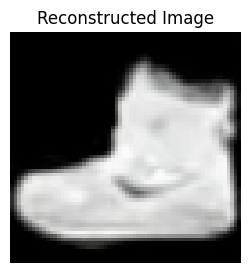

In [18]:
plt.figure(figsize=(3,3))
plt.imshow(recon_img)
plt.title("Reconstructed Image")
plt.axis("off")
plt.show()

## Compare original and reconstruction

If the VAE works well, the reconstructed image should look similar to the original image,
even though the model is working through a compressed latent space.

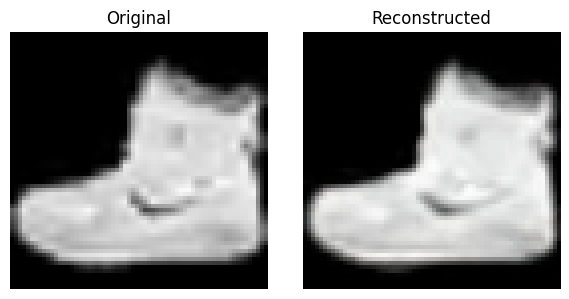

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(6,3))

axes[0].imshow(img_show)
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(recon_img)
axes[1].set_title("Reconstructed")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## What this shows

This demo illustrates the first major idea behind Stable Diffusion:

- the image is compressed into a much smaller latent representation
- the model does not need to work directly on the full image
- this makes diffusion faster and cheaper

In the real Stable Diffusion pipeline, the denoising process happens in this latent space.

# Stable Diffusion Demo 2: Adding Noise in Latent Space

Stable Diffusion works by adding and removing noise in a compressed latent space.  
Instead of corrupting the original image pixels directly, it corrupts the latent representation.

In this demo, we:
1. Load a Fashion-MNIST image
2. Encode it into latent space using the VAE
3. Add different amounts of Gaussian noise to the latent
4. Decode the noisy latents back into images

This helps us understand why denoising in latent space is the core idea of Stable Diffusion.

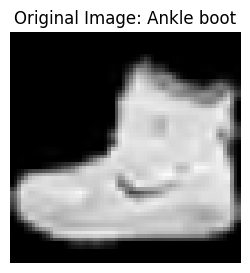

In [20]:
plt.figure(figsize=(3,3))
plt.imshow(img_show)
plt.title(f"Original Image: {class_names[label]}")
plt.axis("off")
plt.show()

## Encode the image into latent space

In [21]:
x = image.unsqueeze(0).to(device)

In [22]:
with torch.no_grad():
    latent_dist = vae.encode(x).latent_dist
    latents = latent_dist.sample() * 0.18215

In [23]:
print("Image shape:", x.shape)
print("Latent shape:", latents.shape)

Image shape: torch.Size([1, 3, 64, 64])
Latent shape: torch.Size([1, 4, 8, 8])


## Add different amounts of noise to the latent

We create several noisy versions of the latent:
- low noise
- medium noise
- high noise

Then we decode them back into images to see how the corruption affects the output.

In [24]:
noise_levels = [0.0, 0.2, 0.5, 0.8, 1.0]
decoded_images = []

In [25]:
with torch.no_grad():
    for alpha in noise_levels:
        noise = torch.randn_like(latents)
        noisy_latent = (1 - alpha) * latents + alpha * noise
        decoded = vae.decode(noisy_latent / 0.18215).sample
        decoded_images.append(decoded[0].cpu())

## Visualize decoded images from noisy latents

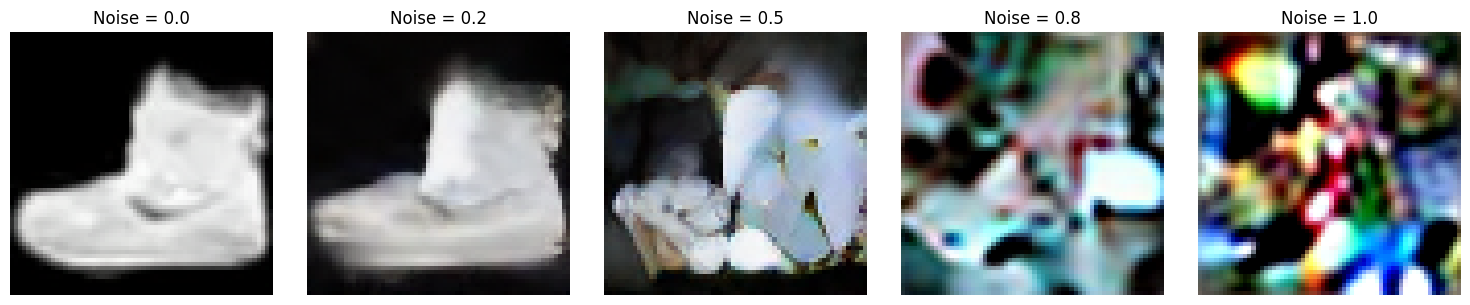

In [26]:
fig, axes = plt.subplots(1, len(noise_levels), figsize=(15,3))

for i, alpha in enumerate(noise_levels):
    img = denorm(decoded_images[i]).permute(1, 2, 0).numpy()
    axes[i].imshow(img)
    axes[i].set_title(f"Noise = {alpha}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

## Compare the original image with noisy latent decodes

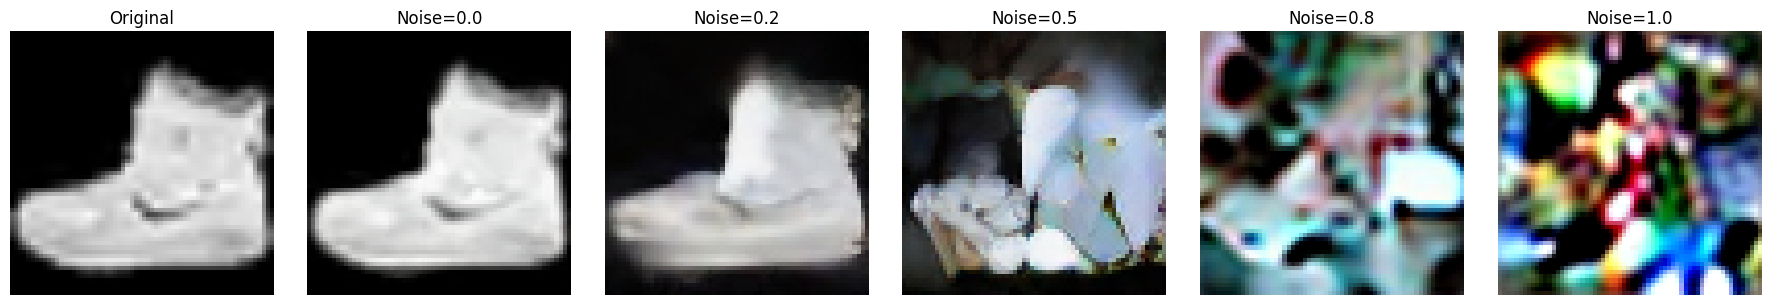

In [27]:
fig, axes = plt.subplots(1, len(noise_levels) + 1, figsize=(18,3))

axes[0].imshow(img_show)
axes[0].set_title("Original")
axes[0].axis("off")

for i, alpha in enumerate(noise_levels):
    img = denorm(decoded_images[i]).permute(1, 2, 0).numpy()
    axes[i+1].imshow(img)
    axes[i+1].set_title(f"Noise={alpha}")
    axes[i+1].axis("off")

plt.tight_layout()
plt.show()

## What this shows

This demo illustrates the second major idea behind Stable Diffusion:

- noise is added in the latent space, not directly in pixel space
- when the latent becomes more noisy, the decoded image becomes more corrupted
- the job of the diffusion model is to gradually remove this noise

In a real Stable Diffusion model, a denoising network learns how to reverse this corruption process step by step.

# Stable Diffusion Demo 3: Learning to Denoise in Latent Space

In Stable Diffusion, images are not denoised directly in pixel space.  
Instead, the image is first compressed into a smaller **latent space** using a VAE, and the denoising model works in that latent space.

In this demo, we will:
1. Load Fashion-MNIST images
2. Convert them to RGB and resize them
3. Encode them into latent space using a pretrained VAE
4. Add noise to the latents
5. Train a tiny CNN to predict the clean latent
6. Decode the denoised latent back into an image

This is a simplified toy version of the main idea behind Stable Diffusion.

In [28]:
train_dataset_full = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

## Use a smaller subset for a faster classroom demo

We do not need the full dataset for this toy example.
<!-- Using a smaller subset makes training much faster in Colab. -->

In [29]:
train_subset = Subset(train_dataset_full, range(2000))
test_subset = Subset(test_dataset, range(200))

In [30]:
BATCH_SIZE = 512

In [31]:
train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
test_loader = DataLoader(test_subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

In [32]:
class_names = train_dataset_full.classes
print(class_names)

['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


## Helper function to display images

In [33]:
def show_tensor_image(img_tensor, title=""):
    img = denorm(img_tensor).permute(1, 2, 0).cpu().numpy()
    plt.figure(figsize=(3, 3))
    plt.imshow(img)
    plt.title(title)
    plt.axis("off")
    plt.show()

## Visualize one input image

In [34]:
sample_img, sample_label = train_dataset_full[0]
print("Image shape:", sample_img.shape)

Image shape: torch.Size([3, 64, 64])


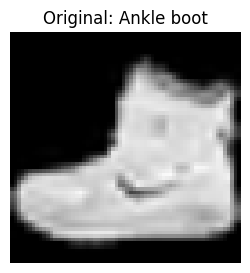

In [35]:
show_tensor_image(sample_img, f"Original: {class_names[sample_label]}")

## Load the pretrained Stable Diffusion VAE

This VAE compresses images into a small latent representation.
That is the space where Stable Diffusion performs denoising.

In [36]:
for param in vae.parameters():
    param.requires_grad = False

## Encode one image into latent space

We will inspect the shape of the latent to see how much smaller it is.

In [37]:
x = sample_img.unsqueeze(0).to(device)

In [38]:
with torch.no_grad():
    latent_dist = vae.encode(x).latent_dist
    latent = latent_dist.sample() * 0.18215

In [39]:
print("Input image shape :", x.shape)
print("Latent shape      :", latent.shape)

Input image shape : torch.Size([1, 3, 64, 64])
Latent shape      : torch.Size([1, 4, 8, 8])


## Decode the latent back into an image

This shows that the latent still keeps the important visual information.

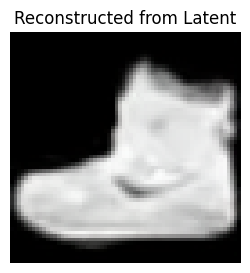

In [40]:
with torch.no_grad():
    recon = vae.decode(latent / 0.18215).sample

show_tensor_image(recon[0], "Reconstructed from Latent")

## Define a tiny latent denoiser

This is a very small CNN.
Its job is simple:

- input: noisy latent + noise level
- output: predicted clean latent

The latent has 4 channels.
We add 1 extra channel containing the noise level, so the input has 5 channels.

In [41]:
class TinyLatentDenoiser(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(5, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 4, kernel_size=3, padding=1)
        )

    def forward(self, noisy_latent, noise_level):
        # noise_level shape: [B]
        # convert it to a spatial map: [B, 1, 8, 8]
        b, _, h, w = noisy_latent.shape
        noise_map = noise_level.view(b, 1, 1, 1).expand(b, 1, h, w)
        x = torch.cat([noisy_latent, noise_map], dim=1)
        return self.net(x)

In [42]:
model = TinyLatentDenoiser().to(device)
print(model)

TinyLatentDenoiser(
  (net): Sequential(
    (0): Conv2d(5, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): ReLU()
    (6): Conv2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): Conv2d(32, 4, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
)


## Training setup

We will:
- encode images into latents using the VAE
- sample a random noise amount
- add noise to the latent
- train the CNN to predict the original clean latent

This is a toy version of latent-space denoising.

In [43]:
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)
epochs = 10

## Training loop

In [44]:
train_losses = []

for epoch in range(epochs):
    model.train()
    running_loss = 0.0

    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}")

    for images, _ in pbar:
        images = images.to(device)

        with torch.no_grad():
            latent_dist = vae.encode(images).latent_dist
            clean_latents = latent_dist.sample() * 0.18215

        # sample random noise level for each image
        noise_level = torch.rand(clean_latents.size(0), device=device)

        # create noisy latents
        noise = torch.randn_like(clean_latents)
        noisy_latents = (1 - noise_level.view(-1, 1, 1, 1)) * clean_latents + \
                        noise_level.view(-1, 1, 1, 1) * noise

        # predict clean latent
        pred_clean = model(noisy_latents, noise_level)

        loss = criterion(pred_clean, clean_latents)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        pbar.set_postfix(loss=loss.item())

    epoch_loss = running_loss / len(train_loader)
    train_losses.append(epoch_loss)
    print(f"Epoch {epoch+1}: loss = {epoch_loss:.4f}")

Epoch 1/10:   0%|          | 0/4 [00:00<?, ?it/s]

Epoch 1: loss = 1.1720


Epoch 2/10:   0%|          | 0/4 [00:00<?, ?it/s]

Epoch 2: loss = 0.9980


Epoch 3/10:   0%|          | 0/4 [00:00<?, ?it/s]

Epoch 3: loss = 0.8972


... (10 outputs left out)

Epoch 9/10:   0%|          | 0/4 [00:00<?, ?it/s]

Epoch 9: loss = 0.4945


Epoch 10/10:   0%|          | 0/4 [00:00<?, ?it/s]

Epoch 10: loss = 0.4555


## Plot training loss

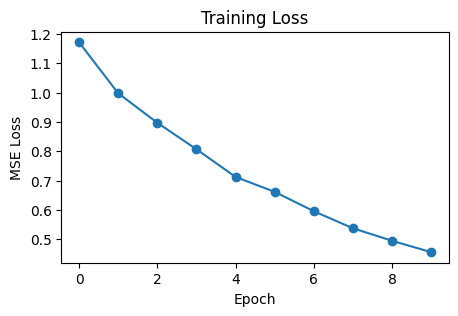

In [45]:
plt.figure(figsize=(5, 3))
plt.plot(train_losses, marker="o")
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.show()

## Test the denoiser on one sample

We will now:
1. take one test image
2. encode it into latent space
3. add noise
4. use the CNN to predict the clean latent
5. decode both the noisy latent and the denoised latent

This helps us compare:
- original image
- noisy latent decode
- denoised latent decode

In [46]:
model.eval()

TinyLatentDenoiser(
  (net): Sequential(
    (0): Conv2d(5, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): ReLU()
    (6): Conv2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): Conv2d(32, 4, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
)

In [47]:
test_img, test_label = test_dataset[0]
test_img_batch = test_img.unsqueeze(0).to(device)

In [48]:
with torch.no_grad():
    clean_latent = vae.encode(test_img_batch).latent_dist.sample() * 0.18215

In [49]:
noise_level_value = 0.4
noise_level = torch.tensor([noise_level_value], device=device)

In [50]:
with torch.no_grad():
    noise = torch.randn_like(clean_latent)
    noisy_latent = (1 - noise_level.view(-1, 1, 1, 1)) * clean_latent + \
                   noise_level.view(-1, 1, 1, 1) * noise

    pred_clean_latent = model(noisy_latent, noise_level)

    decoded_noisy = vae.decode(noisy_latent / 0.18215).sample
    decoded_pred = vae.decode(pred_clean_latent / 0.18215).sample
    decoded_clean = vae.decode(clean_latent / 0.18215).sample

## Visualize the results

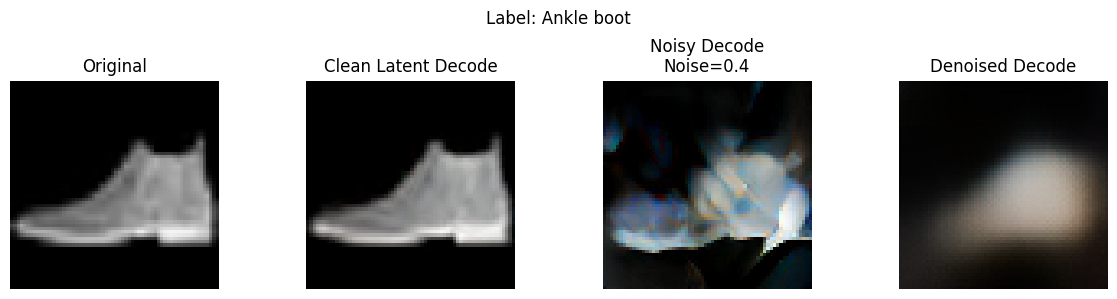

In [51]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3))

fig.suptitle(f"Label: {class_names[test_label]}")

axes[0].imshow(denorm(test_img).permute(1, 2, 0).cpu().numpy())
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(denorm(decoded_clean[0]).permute(1, 2, 0).cpu().numpy())
axes[1].set_title("Clean Latent Decode")
axes[1].axis("off")

axes[2].imshow(denorm(decoded_noisy[0]).permute(1, 2, 0).cpu().numpy())
axes[2].set_title(f"Noisy Decode\nNoise={noise_level_value}")
axes[2].axis("off")

axes[3].imshow(denorm(decoded_pred[0]).permute(1, 2, 0).cpu().numpy())
axes[3].set_title("Denoised Decode")
axes[3].axis("off")

plt.tight_layout()
plt.show()

## Try a few more examples

In [52]:
batch_imgs, batch_labels = next(iter(test_loader))
batch_imgs = batch_imgs[:4].to(device)
batch_labels = batch_labels[:4]

In [53]:
noise_level = torch.full((batch_imgs.size(0),), noise_level_value, device=device)

In [54]:
with torch.no_grad():
    clean_latents = vae.encode(batch_imgs).latent_dist.sample() * 0.18215
    noise = torch.randn_like(clean_latents)
    noisy_latents = (1 - noise_level.view(-1, 1, 1, 1)) * clean_latents + \
                    noise_level.view(-1, 1, 1, 1) * noise

    pred_clean_latents = model(noisy_latents, noise_level)

    decoded_noisy = vae.decode(noisy_latents / 0.18215).sample
    decoded_pred = vae.decode(pred_clean_latents / 0.18215).sample

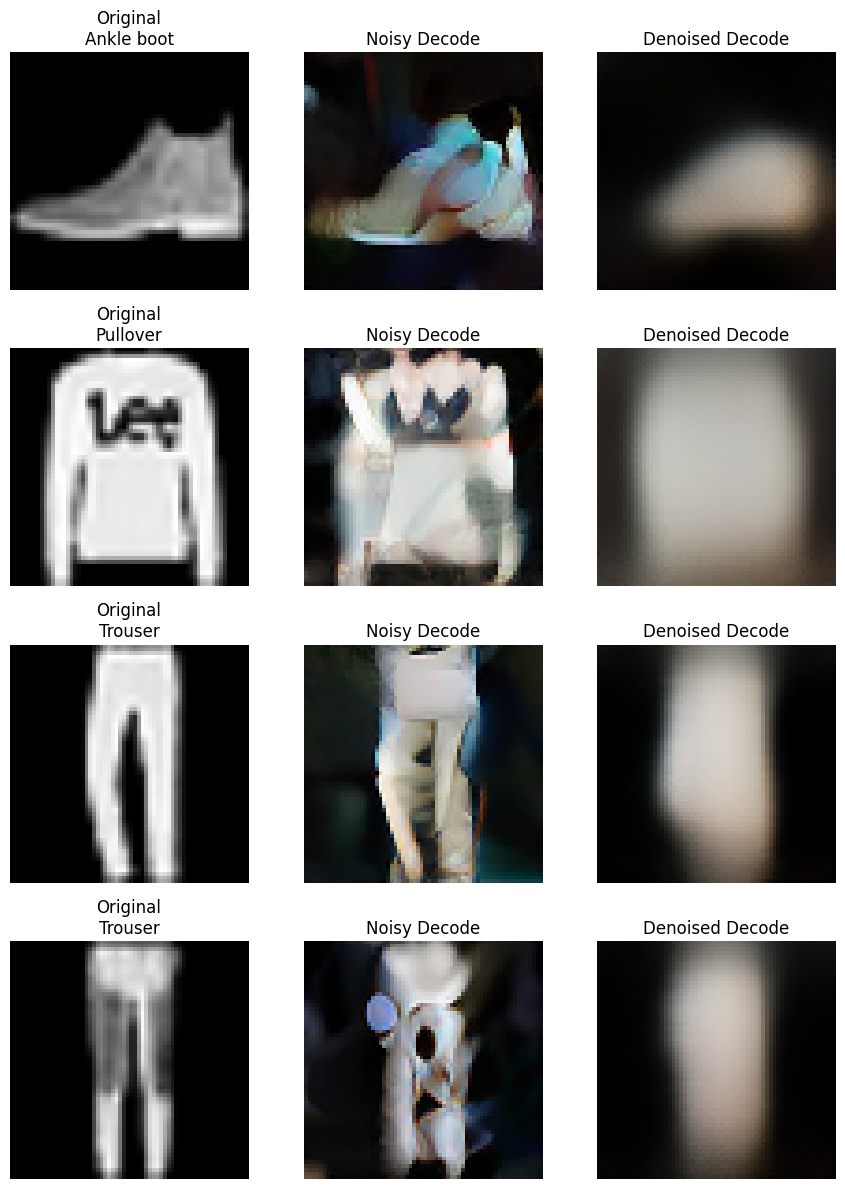

In [55]:
fig, axes = plt.subplots(4, 3, figsize=(9, 12))

for i in range(4):
    axes[i, 0].imshow(denorm(batch_imgs[i]).permute(1, 2, 0).cpu().numpy())
    axes[i, 0].set_title(f"Original\n{class_names[batch_labels[i]]}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(denorm(decoded_noisy[i]).permute(1, 2, 0).cpu().numpy())
    axes[i, 1].set_title("Noisy Decode")
    axes[i, 1].axis("off")

    axes[i, 2].imshow(denorm(decoded_pred[i]).permute(1, 2, 0).cpu().numpy())
    axes[i, 2].set_title("Denoised Decode")
    axes[i, 2].axis("off")

plt.tight_layout()
plt.show()

## What this demo teaches

This toy example demonstrates the core idea behind Stable Diffusion:

- the image is first compressed into a smaller latent space
- noise is added in that latent space
- a neural network learns to remove the noise
- the cleaned latent is decoded back into an image

In the real Stable Diffusion model, the denoiser is much more advanced and also uses text conditioning, but the basic idea is the same.